# Lab 2 — Ứng dụng Pre-trained Models trên CIFAR-10

> **Môn học:** Deep Learning — **Chủ đề:** Transfer Learning & Fine-tuning bằng PyTorch  
> **Tập dữ liệu:** CIFAR-10 (60.000 ảnh màu 32×32, 10 lớp)

Notebook này điều phối toàn bộ quy trình phân loại CIFAR-10 bằng các mô hình pretrained VGG16 và ResNet-18. Trên Colab, nguồn code được lấy từ GitHub; dữ liệu và kết quả cần lưu lâu dài được đặt trên Google Drive.

## Bản tóm tắt nội dung

| Mục | Nội dung | Ghi chú |
|---|---|---|
| **0. Setup & Run Configuration** | Nguồn code, đường dẫn Drive/runtime, chọn `RUN_ID`/`RUN_IDS` | Có thể chạy 1 hoặc nhiều run tuần tự |
| **1. CIFAR-10 Data** | Kiểm tra dữ liệu và tạo train/validation/test loaders | Tạo lại dataloader khi batch size/transform thay đổi |
| **2. Pretrained Architectures** | Khởi tạo và khám phá kiến trúc VGG16, ResNet-18 | `torchinfo.summary` cho cả 2 mô hình |
| **3. CIFAR-10 Model Adaptation** | Classifier, đóng băng backbone, BatchNorm | Điều khiển bởi spec của từng run |
| **4. Training & Validation** | Train/reuse cho từng run được chọn | Chạy tuần tự theo danh sách `RUN_IDS` |
| **5. Model Comparison** | So sánh lịch sử/kết quả các run đã chạy | Tổng hợp sau khi có kết quả |
| **6. Final Test Evaluation** | Đánh giá cuối trên test set | Chỉ sau khi run hoàn tất; không dùng để chọn hyperparameter |

## Quy ước dữ liệu

- CIFAR-10 được chia thành **45.000 train**, **5.000 validation** và **10.000 test**.
- Train dùng để cập nhật weights; validation dùng để chọn checkpoint/cấu hình.
- Test chỉ dùng để đánh giá cuối sau khi mô hình/run đã được chốt.


In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## 0. Setup & Run Configuration

Cell setup phân biệt code checkout, nguồn CIFAR-10 trên Drive, thư mục dữ liệu runtime, artifacts và TensorBoard logs. Cell cấu hình tiếp theo cho phép chọn **một run** (`RUN_ID`) hoặc **nhiều run chạy tuần tự** (`RUN_IDS`).

Ví dụ:
- `RUN_ID = "v1_resnet18"` — chạy 1 run
- `RUN_IDS = ["v0_vgg16", "v1_resnet18"]` — chạy tuần tự 2 run
- `RUN_ID = "v0_vgg16, v1_resnet18"` — chuỗi phân tách dấu phẩy cũng được hỗ trợ

> Lưu ý: `v1_resnet18_finetune` phụ thuộc `v1_resnet18` (cần `best_model.pth` baseline). Khi chạy tuần tự, đặt baseline trước fine-tune.


In [1]:
from pathlib import Path
import subprocess
import sys

GITHUB_REPO_URL = "https://github.com/toan58936/lab2.git"
GITHUB_BRANCH = "main"
GITHUB_COMMIT = None  # Set a commit hash to pin the exact source revision.

try:
    import google.colab
    IS_COLAB = True
except ModuleNotFoundError:
    IS_COLAB = False

if IS_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")

    CODE_ROOT = Path("/content/lab2")
    DRIVE_ROOT = Path("/content/drive/MyDrive/lab2")
    DRIVE_DATA_ROOT = DRIVE_ROOT / "data"
    DRIVE_ARTIFACT_ROOT = DRIVE_ROOT / "artifacts"
    DRIVE_RUNS_ROOT = DRIVE_ROOT / "runs"
    DATA_DIR = Path("/content/cifar10_data")

    if not CODE_ROOT.exists():
        subprocess.run(
            ["git", "clone", "--branch", GITHUB_BRANCH, "--single-branch", GITHUB_REPO_URL, str(CODE_ROOT)],
            check=True,
        )
    elif not (CODE_ROOT / ".git").exists():
        raise FileNotFoundError(
            f"{CODE_ROOT} exists but is not a Git checkout. Rename it before cloning."
        )

    if GITHUB_COMMIT is not None:
        subprocess.run(["git", "-C", str(CODE_ROOT), "checkout", GITHUB_COMMIT], check=True)

    CODE_REVISION = subprocess.run(
        ["git", "-C", str(CODE_ROOT), "rev-parse", "HEAD"],
        check=True,
        capture_output=True,
        text=True,
    ).stdout.strip()
    ARTIFACT_ROOT = DRIVE_ARTIFACT_ROOT
    RUNS_ROOT = DRIVE_RUNS_ROOT
else:
    CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DRIVE_ROOT = None
    DRIVE_DATA_ROOT = None
    DRIVE_ARTIFACT_ROOT = None
    DRIVE_RUNS_ROOT = None
    DATA_DIR = CODE_ROOT / "data"
    ARTIFACT_ROOT = CODE_ROOT / "artifacts"
    RUNS_ROOT = CODE_ROOT / "runs"
    CODE_REVISION = "local working tree"

CODE_ROOT = CODE_ROOT.resolve()
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

print(f"CODE_ROOT      : {CODE_ROOT}")
print(f"CODE_REVISION  : {CODE_REVISION}")
print(f"DRIVE_ROOT     : {DRIVE_ROOT}")
print(f"DRIVE_DATA_ROOT: {DRIVE_DATA_ROOT}")
print(f"DATA_DIR       : {DATA_DIR}")
print(f"ARTIFACT_ROOT  : {ARTIFACT_ROOT}")
print(f"RUNS_ROOT      : {RUNS_ROOT}")
print(f"Colab          : {IS_COLAB}")


Mounted at /content/drive
CODE_ROOT      : /content/lab2
CODE_REVISION  : 986837c81645452e207abd78ee62af8b88a2b9ca
DRIVE_ROOT     : /content/drive/MyDrive/lab2
DRIVE_DATA_ROOT: /content/drive/MyDrive/lab2/data
DATA_DIR       : /content/cifar10_data
ARTIFACT_ROOT  : /content/drive/MyDrive/lab2/artifacts
RUNS_ROOT      : /content/drive/MyDrive/lab2/runs
Colab          : True


In [3]:
!pip install -q torchinfo

import torch
from torch import nn
import torchvision.models as models
import matplotlib.pyplot as plt
import pandas as pd
from timeit import default_timer as timer

try:
    from torch.utils.tensorboard import SummaryWriter
except ImportError:
    raise ImportError('Cài tensorboard: pip install tensorboard')

from going_modular import data_setup, engine, evaluate, model_builder, utils
from torchinfo import summary as torchinfo_summary
from going_modular.model_builder import set_train_mode, count_params

print(f'PyTorch   : {torch.__version__}')
print(f'CUDA      : {torch.cuda.is_available()}')
DEVICE = utils.get_device()
print(f'DEVICE    : {DEVICE}')

PyTorch   : 2.14.1+cu130
CUDA      : True
DEVICE    : cuda


In [16]:
SEED = 42
VAL_SIZE = 5_000
NUM_WORKERS = 0
TRANSFORM_WEIGHTS = "IMAGENET1K_V1"

# ============================================================
# CẤU HÌNH HÀNH ĐỘNG CHO TỪNG RUN (người dùng tự chọn)
# Code KHÔNG tự suy luận dùng trạng thái nào.
#
# Các giá trị action:
#   "train"  : Huấn luyện đầy đủ từ đầu (train mới).
#              - Nếu run đã có artifacts và FORCE_RETRAIN=False -> báo lỗi, không xóa.
#              - Nếu FORCE_RETRAIN=True -> xóa artifacts cũ của run đó rồi train lại từ đầu.
#   "resume" : Tiếp tục từ trạng thái dang dở (phù hợp khi Colab ngắt kết nối).
#              - Yêu cầu có last_checkpoint.pth trong artifacts/<RUN_ID>/.
#              - Kiểm tra done_epochs < target_epochs (spec["epochs"]); nếu đã đủ epoch -> báo lỗi.
#              - engine.train sẽ nạp model/optimizer/history/epoch từ checkpoint và chạy tiếp.
#              - Với fine-tune: KHÔNG nạp baseline v1_resnet18; nạp trạng thái của chính run fine-tune.
#   "reuse"  : Bỏ qua huấn luyện, nạp artifacts đã có (config/history/best_model.pth) để dùng/đánh giá.
#              - Yêu cầu artifacts đầy đủ; run đã train thành công thì chọn action này để không train lại.
#
# RUN_PLAN: đặt action cho từng RUN_ID. RUN_ID không có trong RUN_PLAN sẽ dùng DEFAULT_RUN_ACTION.
# ============================================================
DEFAULT_RUN_ACTION = "train"  # "train" | "resume" | "reuse"
RUN_PLAN = {
    # "v0_vgg16": "train",
    # "v1_resnet18": "resume",
    # "v1_resnet18_finetune": "reuse",
}
FORCE_RETRAIN = False  # True: cho phép xóa artifacts cũ khi action="train" để train lại từ đầu.

ALLOWED_RUN_IDS = (
    "v0_vgg16",
    "v1_resnet18",
    "v1_resnet18_finetune",
)

# Chon 1 run hoac nhieu run chay tuan tu.
# Vi du: RUN_IDS = ["v0_vgg16", "v1_resnet18"]
#        RUN_ID = "v0_vgg16, v1_resnet18" (chuoi phan tach dau phay)
RUN_ID = "v0_vgg16"
RUN_IDS = None  # Neu muon chay nhieu run, dat list o day va bo qua RUN_ID.

def _normalize_run_ids(run_id, run_ids):
    if run_ids is not None:
        items = run_ids
    elif isinstance(run_id, (list, tuple)):
        items = list(run_id)
    elif isinstance(run_id, str) and "," in run_id:
        items = [s.strip() for s in run_id.split(",") if s.strip()]
    else:
        items = [run_id]
    if not items:
        raise ValueError("Danh sach RUN_ID khong duoc rong.")
    normalized = []
    seen = set()
    for rid in items:
        if rid not in ALLOWED_RUN_IDS:
            raise ValueError(f"Unknown RUN_ID {rid!r}; choose one of {ALLOWED_RUN_IDS}.")
        if rid in seen:
            raise ValueError(f"Duplicate RUN_ID in list: {rid!r}.")
        seen.add(rid)
        normalized.append(rid)
    # Kiem tra thu tu phu thuoc: fine-tune phai sau baseline neu ca hai cung duoc chon
    if "v1_resnet18_finetune" in normalized and "v1_resnet18" in normalized:
        if normalized.index("v1_resnet18") > normalized.index("v1_resnet18_finetune"):
            raise ValueError("v1_resnet18 phai duoc chay truoc v1_resnet18_finetune.")
    return normalized

def _get_run_action(run_id):
    action = RUN_PLAN.get(run_id, DEFAULT_RUN_ACTION)
    if action not in {"train", "resume", "reuse"}:
        raise ValueError(f"Action khong hop le cho {run_id}: {action!r}. Chon 'train', 'resume', hoac 'reuse'.")
    return action

RUN_ID_LIST = _normalize_run_ids(RUN_ID, RUN_IDS)

RUN_SPECS = {
    "v0_vgg16": {
        "arch": "vgg16", "weights": "IMAGENET1K_V1", "freeze_backbone": True,
        "unfreeze_last_n": 0, "epochs": 3, "batch_size": 32, "lr": 1e-3,
        "optimizer": "adam", "param_groups": None, "dependency_run_id": None,
    },
    "v1_resnet18": {
        "arch": "resnet18", "weights": "IMAGENET1K_V1", "freeze_backbone": True,
        "unfreeze_last_n": 0, "epochs": 3, "batch_size": 32, "lr": 1e-3,
        "optimizer": "adam", "param_groups": None, "dependency_run_id": None,
    },
    "v1_resnet18_finetune": {
        "arch": "resnet18", "weights": None, "freeze_backbone": True,
        "unfreeze_last_n": 1, "epochs": 3, "batch_size": 32, "lr": 1e-4,
        "optimizer": "adam", "param_groups": {"head": 1e-3, "backbone": 1e-4},
        "dependency_run_id": "v1_resnet18",
        "source_checkpoint": "v1_resnet18/best_model.pth",
    },
}

OUTPUT_ROOT = ARTIFACT_ROOT.parent / "outputs"
LOG_ROOT = ARTIFACT_ROOT.parent / "logs"

# Luu ket qua da chay trong phien de tong hop
run_results = {}

print(f"RUN_IDS         : {RUN_ID_LIST}")
print(f"DEFAULT_ACTION  : {DEFAULT_RUN_ACTION}")
print(f"FORCE_RETRAIN   : {FORCE_RETRAIN}")
print(f"Output root     : {OUTPUT_ROOT}")
print(f"Log root        : {LOG_ROOT}")
print(f"Seed={SEED} | Val_size={VAL_SIZE} | Num_workers={NUM_WORKERS}")
for rid in RUN_ID_LIST:
    print(f"  - {rid}: action={_get_run_action(rid)} | {RUN_SPECS[rid]}")


RUN_ID          : v0_vgg16
RUN_MODE        : train
RESUME          : False
SESSION_ID      : 20261111-090055+0700
EVAL_ID         : 20261111-090055+0700
Output root     : /content/drive/MyDrive/lab2/outputs
Log root        : /content/drive/MyDrive/lab2/logs
Resolved spec   : {'arch': 'vgg16', 'weights': 'IMAGENET1K_V1', 'freeze_backbone': True, 'unfreeze_last_n': 0, 'epochs': 3, 'batch_size': 32, 'lr': 0.001, 'optimizer': 'adam', 'param_groups': None, 'dependency_run_id': None}
Data source     : /content/drive/MyDrive/lab2/data
DataLoader path : /content/cifar10_data
Run artifacts   : /content/drive/MyDrive/lab2/artifacts/v0_vgg16
Guard passed    : RUN_MODE=train | RESUME=False
Seed=42 | Val_size=5000 | Num_workers=0


---
## 1. CIFAR-10 Data

Phần này xác thực dữ liệu CIFAR-10, có thể stage sang thư mục runtime của Colab, rồi tạo DataLoader. Dataset phải có các batch CIFAR-10 chuẩn và `batches.meta`; DataLoader được gọi với `download=False`.

Khi chạy nhiều run tuần tự, dataloader sẽ được tạo lại nếu `batch_size` hoặc kiến trúc transform thay đổi giữa các run.


In [17]:
import shutil
import tarfile
import tempfile
from pathlib import PurePosixPath

_CIFAR_REQUIRED_FILES = {
    "data_batch_1", "data_batch_2", "data_batch_3", "data_batch_4",
    "data_batch_5", "test_batch", "batches.meta",
}

def _valid_cifar10_directory(path: Path) -> bool:
    return path.is_dir() and _CIFAR_REQUIRED_FILES.issubset(
        {item.name for item in path.iterdir() if item.is_file()}
    )

def _stage_cifar10_from_drive() -> None:
    destination = DATA_DIR / "cifar-10-batches-py"
    if _valid_cifar10_directory(destination):
        return
    if destination.exists():
        raise FileExistsError(
            f"Incomplete CIFAR-10 directory at {destination}; it will not be overwritten."
        )
    source_directory = DRIVE_DATA_ROOT / "cifar-10-batches-py"
    if not _valid_cifar10_directory(source_directory) and _valid_cifar10_directory(DRIVE_DATA_ROOT):
        source_directory = DRIVE_DATA_ROOT

    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if _valid_cifar10_directory(source_directory):
        shutil.copytree(source_directory, destination)
    else:
        archive_path = DRIVE_DATA_ROOT / "cifar-10-python.tar.gz"
        if not archive_path.is_file():
            raise FileNotFoundError(
                "CIFAR-10 was not found on Drive. Upload either "
                f"{source_directory} or {archive_path}."
            )
        with tempfile.TemporaryDirectory(prefix="cifar10_stage_") as temporary_directory:
            with tarfile.open(archive_path, "r:gz") as archive:
                members = archive.getmembers()
                for member in members:
                    member_path = PurePosixPath(member.name)
                    if (
                        member_path.is_absolute()
                        or ".." in member_path.parts
                        or not member_path.parts
                        or member_path.parts[0] != "cifar-10-batches-py"
                        or not (member.isfile() or member.isdir())
                    ):
                        raise ValueError(
                            f"Unexpected or unsafe member in CIFAR-10 archive: {member.name}"
                        )
                archive.extractall(temporary_directory, members=members)
            extracted_directory = Path(temporary_directory) / "cifar-10-batches-py"
            if not _valid_cifar10_directory(extracted_directory):
                raise ValueError(
                    f"The archive does not contain a valid CIFAR-10 dataset: {archive_path}"
                )
            shutil.copytree(extracted_directory, destination)
    if not _valid_cifar10_directory(destination):
        raise ValueError(f"Staged CIFAR-10 dataset is incomplete: {destination}")

if IS_COLAB:
    _stage_cifar10_from_drive()
elif not _valid_cifar10_directory(DATA_DIR / "cifar-10-batches-py"):
    raise FileNotFoundError(
        f"CIFAR-10 files were not found under {DATA_DIR}; prepare the dataset before loading."
    )

def create_dataloaders_for_spec(spec):
    """Tao (train_dl, val_dl, test_dl, CLASS_NAMES) theo spec cua run."""
    return data_setup.create_train_val_test_dataloaders(
        batch_size=spec["batch_size"],
        data_dir=str(DATA_DIR),
        transform_model=spec["arch"],
        transform_weights=TRANSFORM_WEIGHTS,
        val_size=VAL_SIZE,
        seed=SEED,
        num_workers=NUM_WORKERS,
        download=False,
    )

print("CIFAR-10 data ready. Dataloaders se duoc tao cho tung run khi can.")


Classes (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train batches :  1407  (~ 45024 samples)
Val batches   :   157  (~  5024 samples)
Test batches  :   313  (~ 10016 samples)


In [18]:
# -- Kiem tra batch cho run dau tien trong danh sach --
_first_spec = RUN_SPECS[RUN_ID_LIST[0]]
train_dl, val_dl, test_dl, CLASS_NAMES = create_dataloaders_for_spec(_first_spec)
NUM_CLASSES = len(CLASS_NAMES)

images, labels = next(iter(train_dl))
print(f'Run inspect   : {RUN_ID_LIST[0]} (batch_size={_first_spec["batch_size"]})')
print(f'Classes ({NUM_CLASSES}): {CLASS_NAMES}')
print(f'Train batches : {len(train_dl):>5}')
print(f'Val batches   : {len(val_dl):>5}')
print(f'Test batches  : {len(test_dl):>5}')
print(f'Batch images  : {images.shape}   # [B, C, H, W]')
print(f'Batch labels  : {labels.shape}')
print(f'Pixel range   : [{images.min():.3f}, {images.max():.3f}]')


Batch images : torch.Size([32, 3, 224, 224])   # [B, C, H, W]
Batch labels : torch.Size([32])
Dtype        : torch.float32
Pixel range (ImageNet-normalized): [-2.118, 2.640]


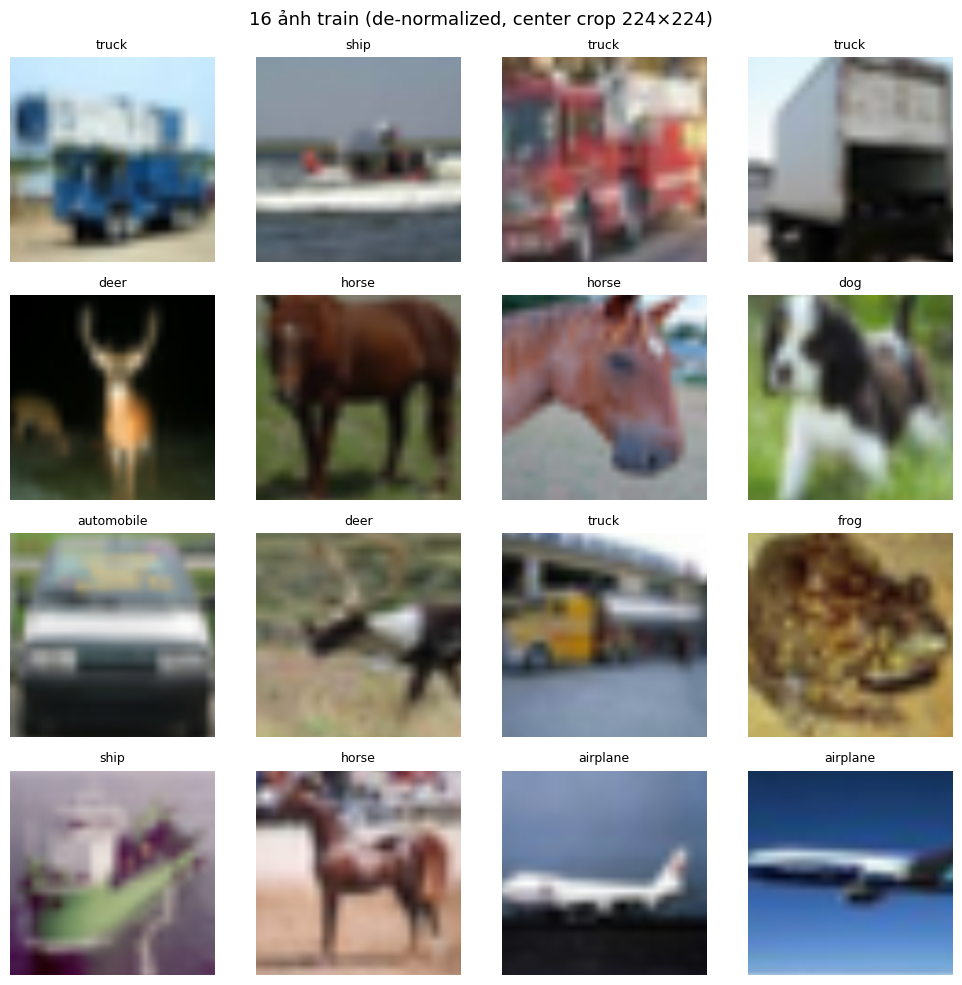

In [9]:
# -- De-normalize để hiển thị ảnh --
# Tensor đã normalize theo ImageNet, cần đảo ngược trước khi plt.imshow()
from torchvision.models import VGG16_Weights
WEIGHT_TRANSFORM = VGG16_Weights.IMAGENET1K_V1.transforms()
IMAGENET_MEAN = torch.tensor(WEIGHT_TRANSFORM.mean).view(3, 1, 1)
IMAGENET_STD  = torch.tensor(WEIGHT_TRANSFORM.std).view(3, 1, 1)

def denormalize(t):
    """[C,H,W] normalized → [C,H,W] in [0,1]"""
    return (t * IMAGENET_STD + IMAGENET_MEAN).clamp(0.0, 1.0)

torch.manual_seed(SEED)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, img, lbl in zip(axes.flat, images[:16], labels[:16]):
    ax.imshow(denormalize(img).permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[lbl.item()], fontsize=9)
    ax.axis('off')
fig.suptitle('16 ảnh train (de-normalized, center crop 224×224)', fontsize=13)
plt.tight_layout()
plt.show()

---
## 2. Pretrained Architectures

Phần này khởi tạo và khám phá kiến trúc VGG16, ResNet-18 kèm ImageNet weights, sau đó xem cấu trúc và số lượng tham số. Ở chế độ train, việc tải pretrained weights cần mạng và thuộc giai đoạn thực nghiệm.

Trong Phase 8, không chạy các cell khởi tạo model nếu chưa tải weights; chỉ hoàn thiện cấu hình notebook.



In [19]:
# ============================================================
# Kham pha kien truc VGG16, ResNet-18 (Step 3)
# Hien thi torchinfo.summary cho ca 2 mo hinh de thay ro cac lop.
# ============================================================
from going_modular.model_builder import ModelConfig, build_model, get_param_groups

utils.set_seed(SEED)

for arch_name in ["resnet18", "vgg16"]:
    cfg_explore = ModelConfig(arch=arch_name, num_classes=NUM_CLASSES, weights=None, freeze_backbone=True)
    model_explore = build_model(cfg_explore)
    print("=" * 70)
    print(f"Kien truc: {arch_name} | num_classes={NUM_CLASSES} | freeze_backbone=True")
    print("=" * 70)
    print(torchinfo_summary(
        model=model_explore,
        input_size=(1, 3, 224, 224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"],
        depth=3,
    ))
    print()

def build_model_for_run(run_id, spec, action, resume_flag=False):
    """Dung model cho mot run.
    - action='train' (fresh): tai weights theo spec; fine-tune nap baseline checkpoint.
    - action='resume': khoi tao cau truc (weights=None) de engine nap last_checkpoint.pth.
    - action='reuse': khoi tao cau truc (weights=None) de nap best_model.pth cua run.
    """
    if action == "train" and not resume_flag:
        load_weights = spec["weights"]
    else:
        # resume/reuse: state se duoc nap tu checkpoint/best_model cua run
        load_weights = None

    cfg = ModelConfig(
        arch=spec["arch"],
        num_classes=NUM_CLASSES,
        weights=load_weights,
        freeze_backbone=spec["freeze_backbone"],
        unfreeze_last_n=spec["unfreeze_last_n"],
    )
    model = build_model(cfg).to(DEVICE)

    # Fine-tune train mới: nap checkpoint baseline truoc khi train
    if action == "train" and not resume_flag and spec.get("dependency_run_id") is not None:
        baseline_path = ARTIFACT_ROOT / spec["source_checkpoint"]
        if not baseline_path.is_file():
            raise FileNotFoundError(
                f"{run_id} yeu cau baseline checkpoint: {baseline_path}. "
                f"Hay chay baseline '{spec['dependency_run_id']}' truoc."
            )
        utils.load_model(model, str(baseline_path), device=DEVICE)
        print(f"  Loaded baseline checkpoint for fine-tune: {baseline_path}")

    # Fine-tune resume/reuse: khong nap baseline; se nap checkpoint/best cua chinh run
    if action in {"resume", "reuse"} and spec.get("dependency_run_id") is not None:
        print(f"  {run_id}: se nap trang thai cua chinh run (khong nap baseline).")

    return model, cfg


v0_vgg16 | vgg16 | weights=IMAGENET1K_V1 | freeze_backbone=True
v0_vgg16 output: torch.Size([2, 10])
v0_vgg16 classifier (head):
Linear(in_features=25088, out_features=10, bias=True)


---
## 3. CIFAR-10 Model Adaptation

Phần này minh họa thay lớp classifier để tạo đầu ra 10 lớp, đóng băng backbone và giữ BatchNorm ở trạng thái phù hợp khi train.

| Chiến lược | Nghĩa |
|---|---|
| **Feature extraction** | Đóng băng backbone, chỉ cập nhật classifier mới |
| **Fine-tuning** | Mở khóa một hoặc nhiều block cuối và cập nhật cùng classifier (chỉ `v1_resnet18_finetune`, khởi tạo từ baseline `v1_resnet18`) |
| **Full training** | Cập nhật toàn bộ mạng; không dùng trong các run hiện tại |

Các cell model/train/eval được điều khiển bởi `RUN_SPECS` và chạy tuần tự theo `RUN_IDS`.


---
## 4. Training & Validation — train/reuse tuần tự cho từng RUN_ID

Phần này chạy train hoặc reuse cho từng `RUN_ID` trong `RUN_IDS` theo thứ tự. Mỗi run có artifact, output và log riêng.

- `v1_resnet18_finetune` yêu cầu `v1_resnet18/best_model.pth` đã hoàn tất (baseline sẽ được nạp vào model trước khi fine-tune).
- Dataloader được tạo lại khi `batch_size`/`transform_model` thay đổi.
- `verbose=True` để hiển thị tiến trình từng epoch.


In [20]:
def log_run_config(writer, config: dict):
    """Ghi run config vao TensorBoard text tab."""
    lines = [f'`{k}` = `{v}`' for k, v in config.items()]
    writer.add_text('run_config', '  \n'.join(lines), global_step=0)

loss_fn = nn.CrossEntropyLoss()


---
### 4.1. Train/Reuse cho từng RUN_ID

Huấn luyện hoặc nạp lại artifact cho từng run qua `engine.train`.


In [21]:
# ============================================================
# Train/resume/reuse tuan tu cho tung RUN_ID trong RUN_ID_LIST
# Hanh dong do nguoi dung chon (RUN_PLAN / DEFAULT_RUN_ACTION).
# ============================================================
from going_modular.model_builder import get_param_groups

run_results = globals().get("run_results", {})

for RUN_ID in RUN_ID_LIST:
    spec = RUN_SPECS[RUN_ID]
    action = _get_run_action(RUN_ID)
    BATCH_SIZE = spec["batch_size"]
    EPOCHS = spec["epochs"]
    LR = spec["lr"]

    RUN_ARTIFACT_DIR = ARTIFACT_ROOT / RUN_ID
    RUN_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    CONFIG_PATH = RUN_ARTIFACT_DIR / "config.json"
    HISTORY_PATH = RUN_ARTIFACT_DIR / "history.json"
    BEST_MODEL_PATH = RUN_ARTIFACT_DIR / "best_model.pth"
    LAST_CHECKPOINT_PATH = RUN_ARTIFACT_DIR / "last_checkpoint.pth"
    TEST_METRICS_PATH = RUN_ARTIFACT_DIR / "test_metrics.json"

    def _artifact_files_present():
        return all(p.is_file() for p in [CONFIG_PATH, HISTORY_PATH, BEST_MODEL_PATH])

    # --- Xac thuc action va trang thai artifacts (khong tu suy luan) ---
    if action == "train":
        if _artifact_files_present():
            if not FORCE_RETRAIN:
                raise FileExistsError(
                    f"{RUN_ID}: artifacts da ton tai tai {RUN_ARTIFACT_DIR}. "
                    "Action='train' se khong tu xoa. Dat FORCE_RETRAIN=True de train lai tu dau, "
                    "hoac chon action='resume'/'reuse'."
                )
            print(f"[FORCE_RETRAIN] {RUN_ID}: xoa artifacts cu va train lai tu dau...")
            for f in [CONFIG_PATH, HISTORY_PATH, BEST_MODEL_PATH, LAST_CHECKPOINT_PATH, TEST_METRICS_PATH]:
                if f.is_file():
                    f.unlink()
        resume_flag = False

    elif action == "resume":
        if not LAST_CHECKPOINT_PATH.is_file():
            raise FileNotFoundError(
                f"{RUN_ID}: action='resume' yeu cau last_checkpoint.pth: {LAST_CHECKPOINT_PATH}. "
                "Neu chua co checkpoint, chon action='train'. Neu da hoan tat, chon action='reuse'."
            )
        # Doc checkpoint de bao cao tien do (engine cung kiem tra khi resume)
        _ckpt = torch.load(str(LAST_CHECKPOINT_PATH), map_location="cpu")
        done_epochs = int(_ckpt.get("phase_epochs_completed", 0))
        target_epochs = int(EPOCHS)
        if done_epochs >= target_epochs:
            raise ValueError(
                f"{RUN_ID}: da hoan tat {done_epochs}/{target_epochs} epochs, khong can resume. "
                "Chon action='reuse' hoac tang EPOCHS trong spec neu muon train them."
            )
        print(f"{RUN_ID}: resume tu epoch {done_epochs}/{target_epochs}")
        resume_flag = True

    elif action == "reuse":
        if not _artifact_files_present():
            missing = [str(p) for p in [CONFIG_PATH, HISTORY_PATH, BEST_MODEL_PATH] if not p.is_file()]
            raise FileNotFoundError(
                f"{RUN_ID}: action='reuse' yeu cau artifacts day du nhung thieu: {missing}. "
                "Hay chon action='train' hoac 'resume'."
            )
        resume_flag = False

    else:
        raise ValueError(f"Action khong ho tro: {action}")

    # --- Dated outputs/session logs per-run ---
    SESSION_ID = utils.make_session_id()
    EVAL_ID = utils.make_eval_id()
    EVAL_OUTPUT_DIR = utils.make_eval_output_dir(OUTPUT_ROOT, RUN_ID, eval_id=EVAL_ID)
    EVAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # --- Dataloader per-run (batch_size/arch co the khac) ---
    train_dl, val_dl, test_dl, _ = create_dataloaders_for_spec(spec)

    # --- Build model per-run ---
    utils.set_seed(SEED)
    model_selected, cfg_selected = build_model_for_run(RUN_ID, spec, action, resume_flag=resume_flag)

    if action in {"train", "resume"}:
        # Optimizer
        if spec["param_groups"] is not None:
            param_groups = get_param_groups(model_selected, cfg_selected,
                                            spec["param_groups"]["head"],
                                            spec["param_groups"]["backbone"])
            optimizer_selected = torch.optim.Adam(param_groups, lr=LR)
        else:
            optimizer_selected = torch.optim.Adam(
                filter(lambda p: p.requires_grad, model_selected.parameters()), lr=LR
            )

        # Train-mode callback (BN freeze cho backbone khi freeze)
        train_mode_fn = None
        if spec["freeze_backbone"]:
            train_mode_fn = lambda m, c=cfg_selected: set_train_mode(m, c)

        writer_selected = SummaryWriter(log_dir=str(utils.make_session_log_dir(LOG_ROOT, RUN_ID, SESSION_ID)))

        RUN_CONFIG = {
            "run_id": RUN_ID,
            "model": spec["arch"],
            "weights": spec["weights"],
            "data": {"transform_model": spec["arch"], "transform_weights": TRANSFORM_WEIGHTS},
            "num_classes": NUM_CLASSES,
            "freeze_backbone": spec["freeze_backbone"],
            "unfreeze_last_n": spec["unfreeze_last_n"],
            "batch_size": BATCH_SIZE,
            "lr": LR,
            "epochs": EPOCHS,
            "seed": SEED,
            "action": action,
            "resume": resume_flag,
        }

        print("-" * 55)
        print(f"{RUN_ID} | action={action} | resume={resume_flag} | epochs_target={EPOCHS}")
        print("-" * 55)

        start_time = timer()
        try:
            history_selected = engine.train(
                model=model_selected,
                train_dataloader=train_dl,
                val_dataloader=val_dl,
                optimizer=optimizer_selected,
                loss_fn=loss_fn,
                epochs=EPOCHS,
                device=DEVICE,
                writer=writer_selected,
                save_path=str(BEST_MODEL_PATH),
                checkpoint_dir=str(RUN_ARTIFACT_DIR),
                resume=resume_flag,
                expected_phase_config=RUN_CONFIG,
                start_epoch=0,
                train_mode_fn=train_mode_fn,
                verbose=True,
            )
        finally:
            writer_selected.close()

        train_time = timer() - start_time
        RUN_CONFIG["train_seconds"] = train_time
        utils.save_config(str(RUN_ARTIFACT_DIR), RUN_CONFIG)
        utils.save_history(str(RUN_ARTIFACT_DIR), history_selected)

        best_val_acc = max(history_selected["val_acc"])
        print(f"{RUN_ID} ready | action={action} | train time: {train_time:.1f}s | best val_acc: {best_val_acc:.4f}")

    else:
        # reuse
        history_selected, saved_config_selected = utils.load_experiment(str(RUN_ARTIFACT_DIR))
        utils.load_model(model_selected, str(BEST_MODEL_PATH), device=DEVICE)
        train_time = float(saved_config_selected.get("train_seconds", 0.0))
        best_val_acc = max(history_selected["val_acc"]) if history_selected.get("val_acc") else 0.0
        print(f"{RUN_ID} reused | train time: {train_time:.1f}s | best val_acc: {best_val_acc:.4f}")

    run_results[RUN_ID] = {
        "model": model_selected,
        "history": history_selected,
        "best_val_acc": best_val_acc,
        "train_time": train_time,
        "spec": spec,
        "action": action,
        "eval_output_dir": EVAL_OUTPUT_DIR,
        "artifact_dir": RUN_ARTIFACT_DIR,
        "test_dl": test_dl,
    }

# Luu bien toan cuc
globals()["run_results"] = run_results
if RUN_ID_LIST:
    _last = RUN_ID_LIST[-1]
    globals()["RUN_ID"] = _last
    globals()["model_selected"] = run_results[_last]["model"]
    globals()["history_selected"] = run_results[_last]["history"]
    globals()["best_val_acc_selected"] = run_results[_last]["best_val_acc"]
    globals()["train_time_selected"] = run_results[_last]["train_time"]
    globals()["EVAL_OUTPUT_DIR"] = run_results[_last]["eval_output_dir"]

print(f"\nDa hoan tat {len(run_results)} run: {list(run_results.keys())}")


-------------------------------------------------------
v0_vgg16 | mode=train | resume=False | start_epoch=0
-------------------------------------------------------
v0_vgg16 ready | train time: 1073.2s | best val_acc: 0.8472


---
### 4.2. Cấu hình BatchNorm khi freeze backbone

Khi `freeze_backbone=True`, `set_train_mode` giữ BatchNorm của backbone ở `eval` trong toàn bộ quá trình train.



---
## 5. Model Comparison — tổng hợp các run đã chạy

Phần này tóm tắt và so sánh lịch sử/metrics của các run đã chạy trong phiên (hoặc nạp từ artifacts nếu cần).


In [23]:
# ============================================================
# Tong hop ket qua cac run da chay
# ============================================================
if run_results:
    rows = []
    for rid, res in run_results.items():
        rows.append({
            'Run': rid,
            'Best val_acc': f'{res["best_val_acc"]:.4f}',
            'Train time (s)': f'{res["train_time"]:.1f}',
            'Trainable params': f"{count_params(res['model'])['trainable']:,}",
            'Epochs': res["spec"]["epochs"],
            'Batch': res["spec"]["batch_size"],
            'LR': res["spec"]["lr"],
        })
    df_summary = pd.DataFrame(rows).set_index('Run')
    print(df_summary)
else:
    print("Chua co ket qua run nao. Hay chay cell train/reuse truoc.")


         Best val_acc Train time (s) Trainable params
Run                                                  
v0_vgg16       0.8472         1073.2          250,890


[INFO] Saved figure to: /content/drive/MyDrive/lab2/outputs/2026-11-11/v0_vgg16/20261111-090055+0700/history.png


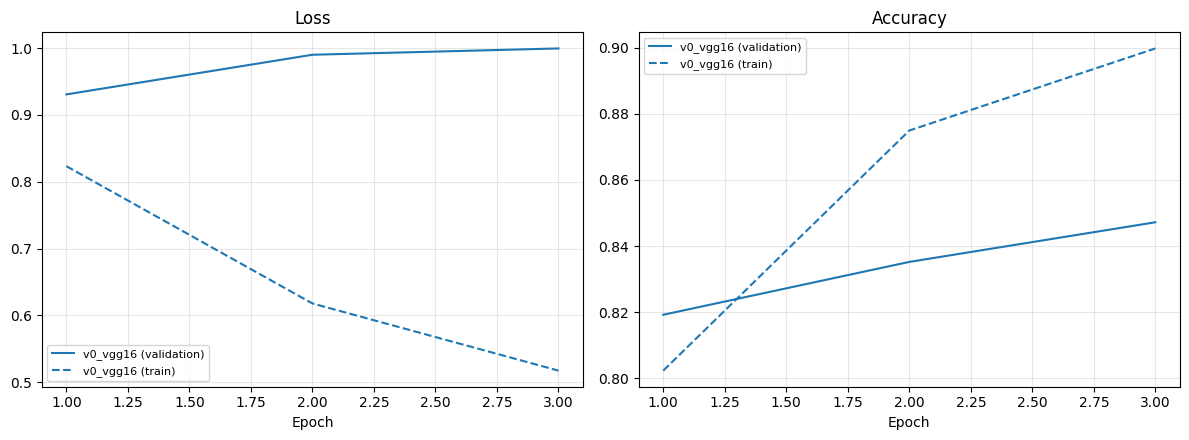

In [24]:
# ============================================================
# Ve loss/accuracy curves cho cac run da chay
# ============================================================
if run_results:
    histories = {rid: res["history"] for rid, res in run_results.items() if res.get("history")}
    if histories:
        # Luu plot tong hop vao outputs cua run cuoi
        last_rid = list(run_results.keys())[-1]
        save_path = str(run_results[last_rid]["eval_output_dir"] / "history_comparison.png")
        evaluate.plot_history(histories=histories, save_path=save_path, show=True)
    else:
        print("Khong co history de ve.")
else:
    print("Chua co ket qua run nao. Hay chay cell train/reuse truoc.")


---
## 6. Final Test Evaluation — đánh giá cuối cho từng run đã hoàn tất

> **Chỉ chạy sau khi quá trình huấn luyện/reuse và lựa chọn checkpoint bằng validation đã hoàn tất.** Không sử dụng kết quả test để chọn kiến trúc, hyperparameter hay checkpoint.

Phần này chạy inference một lần cho mỗi run, tính metrics, confusion matrix, per-class accuracy, top confusions và vẽ dự đoán sai. Kết quả lưu vào `outputs/<date>/<RUN_ID>/<EVAL_ID>/`.


In [ ]:
# ============================================================
# Danh gia test cho tung run da chay (1 lan inference/run)
# ============================================================
from going_modular.evaluate import run_inference, evaluate_predictions, predict_dataloader, compute_confusion_matrix

for RUN_ID, res in run_results.items():
    model = res["model"]
    eval_dir = res["eval_output_dir"]
    test_dl = res["test_dl"]
    metrics_path = eval_dir / "test_metrics.json"

    # Inference 1 lan
    model.eval()
    inf = run_inference(model, test_dl, DEVICE, loss_fn=loss_fn)
    y_true = inf.y_true
    y_pred = inf.y_pred

    result = evaluate_predictions(inf, CLASS_NAMES)
    res["test_result"] = result
    res["y_true"] = y_true
    res["y_pred"] = y_pred

    # Luu metrics neu chua co
    if not metrics_path.is_file():
        utils.save_test_metrics(str(eval_dir), result)
        print(f"[{RUN_ID}] Da luu: {metrics_path}")
    else:
        cached = utils.load_test_metrics(str(eval_dir))
        if cached:
            result = cached
            res["test_result"] = result
        print(f"[{RUN_ID}] test_metrics.json da ton tai, su dung ban luu.")

    print(f"=== TEST SET RESULTS: {RUN_ID} ===")
    for k, v in result.items():
        print(f"  {k}: {v}")
    print()


In [ ]:
# ============================================================
# Confusion matrix cho tung run
# ============================================================
for RUN_ID, res in run_results.items():
    if "y_true" not in res or "y_pred" not in res:
        print(f"[{RUN_ID}] Chua co ket qua inference, bo qua.")
        continue
    cm = compute_confusion_matrix(y_true=res["y_true"], y_pred=res["y_pred"], num_classes=NUM_CLASSES)
    res["cm"] = cm
    evaluate.plot_confusion_matrix(
        cm,
        class_names=CLASS_NAMES,
        title=f'Confusion Matrix — {RUN_ID} (Test Set)',
        save_path=str(res["eval_output_dir"] / "confusion_matrix.png"),
        show=True,
    )


In [ ]:
# ============================================================
# Per-class accuracy cho tung run
# ============================================================
for RUN_ID, res in run_results.items():
    if "cm" not in res:
        if "y_true" in res and "y_pred" in res:
            res["cm"] = compute_confusion_matrix(y_true=res["y_true"], y_pred=res["y_pred"], num_classes=NUM_CLASSES)
        else:
            print(f"[{RUN_ID}] Chua co ket qua, bo qua.")
            continue
    class_acc = evaluate.per_class_accuracy(res["cm"])
    df_class = pd.DataFrame({
        'Class': CLASS_NAMES,
        'Accuracy': [f'{a:.3f}' for a in class_acc.tolist()],
    }).sort_values('Accuracy')
    print(f'--- {RUN_ID} Per-class accuracy (thap -> cao) ---')
    print(df_class.to_string(index=False))
    print()


In [ ]:
# ============================================================
# Top 5 nham lan cho tung run
# ============================================================
for RUN_ID, res in run_results.items():
    if "cm" not in res:
        print(f"[{RUN_ID}] Chua co confusion matrix, bo qua.")
        continue
    top5 = evaluate.top_confusions(res["cm"], CLASS_NAMES, k=5)
    print(f'--- {RUN_ID} Top 5 nham lan ---')
    print(f'  {"True":>12} -> {"Predicted":<12}  Count')
    print('  ' + '-' * 38)
    for true_cls, pred_cls, count in top5:
        print(f'  {true_cls:>12} -> {pred_cls:<12}  {count}')
    print()


In [ ]:
# ============================================================
# Visualize du doan sai cho tung run
# ============================================================
from going_modular.evaluate import denormalize as eval_denormalize

for RUN_ID, res in run_results.items():
    if "y_true" not in res or "y_pred" not in res:
        print(f"[{RUN_ID}] Chua co ket qua, bo qua.")
        continue
    y_true_t = res["y_true"]
    y_pred_t = res["y_pred"]
    test_dl = res["test_dl"]

    wrong_mask = (y_pred_t != y_true_t)
    wrong_indices = wrong_mask.nonzero(as_tuple=True)[0][:9]
    if len(wrong_indices) == 0:
        print(f"[{RUN_ID}] Khong co du doan sai.")
        continue

    # Thu thap tat ca anh tu test_dl (theo thu tu)
    all_imgs = []
    for imgs, _ in test_dl:
        all_imgs.append(imgs)
    all_imgs = torch.cat(all_imgs)

    # Lay mean/std tu transform weights
    from torchvision.models import VGG16_Weights
    wt = VGG16_Weights.IMAGENET1K_V1.transforms()
    # weights transforms store mean/std internally; fallback to ImageNet defaults
    mean = torch.tensor([0.485, 0.456, 0.406])
    std = torch.tensor([0.229, 0.224, 0.225])

    sample_imgs = [eval_denormalize(all_imgs[i], mean, std) for i in wrong_indices]
    sample_true = [y_true_t[i].item() for i in wrong_indices]
    sample_pred = [y_pred_t[i].item() for i in wrong_indices]

    evaluate.plot_sample_predictions(
        images=sample_imgs,
        true_labels=sample_true,
        pred_labels=sample_pred,
        class_names=CLASS_NAMES,
        ncols=3,
        save_path=str(res["eval_output_dir"] / "sample_predictions.png"),
        show=True,
    )


---
## Trạng thái và bước tiếp theo

### Cấu hình & chạy
- Notebook hỗ trợ chạy **1 hoặc nhiều run tuần tự** qua `RUN_ID`/`RUN_IDS`.
- Mỗi run: build model/dataloader theo spec → train/resume/reuse (do người dùng chọn) → lưu artifacts (`config.json`, `history.json`, `best_model.pth`, `last_checkpoint.pth`) → đánh giá test và lưu outputs.
- Fine-tune `v1_resnet18_finetune` tự nạp baseline `v1_resnet18/best_model.pth` khi train mới (cần chạy baseline trước hoặc chọn `resume`/`reuse` nếu đã có checkpoint của run fine-tune).

### Thứ tự gợi ý
1. `v0_vgg16`, `v1_resnet18` (feature extraction)
2. `v1_resnet18_finetune` (sau khi `v1_resnet18` hoàn tất) — run fine-tune duy nhất

### Lưu ý
- `epochs=3` là cấu hình thử nghiệm nhanh; có thể tăng lên 5 cho feature extraction khi chạy chính thức.
- Test set chỉ dùng đánh giá cuối, không dùng chọn checkpoint/hyperparameter.
- TensorBoard logs: `logs/<RUN_ID>/<SESSION_ID>/` (chạy `tensorboard --logdir=logs` để xem).
